# Telecom Customer Churn Analysis
## 05 — Customer Churn Visualizations

This section visualizes the main findings from the exploratory data analysis and SQL analysis. The charts focus on customer status, contract type, tenure, and reported churn reasons.

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the cleaned dataset
df_clean = pd.read_csv("../data/telecom_customer_churn_clean.csv")

# Check the data
print("Dataset shape:", df_clean.shape)
print(df_clean["Customer Status"].value_counts())


Dataset shape: (7043, 38)
Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


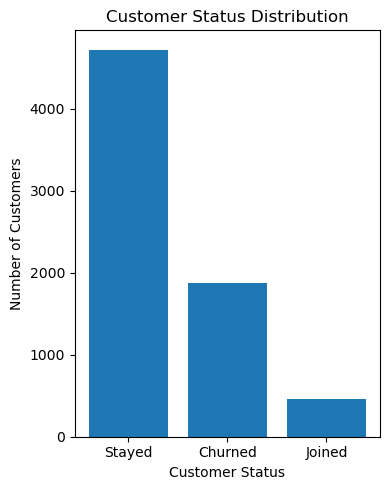

In [8]:
# Visualize the customer status groups

status_counts = df_clean["Customer Status"].value_counts()

plt.figure(figsize=(4, 5))
plt.bar(status_counts.index, status_counts.values)

plt.title("Customer Status Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


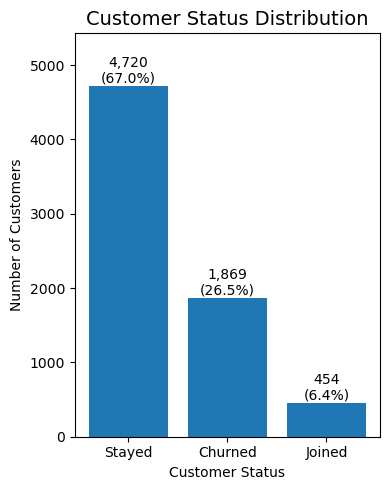

In [10]:
status_counts = df_clean["Customer Status"].value_counts()
status_percentages = status_counts / len(df_clean) * 100

plt.figure(figsize=(4, 5))
bars = plt.bar(status_counts.index, status_counts.values)

plt.title("Customer Status Distribution", fontsize=14)
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

# Add count and percentage labels above each bar
for bar, count, percentage in zip(
    bars, status_counts.values, status_percentages.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.ylim(0, status_counts.max() * 1.15)
plt.tight_layout()

# Save the chart
plt.savefig(
    "../images/01_customer_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


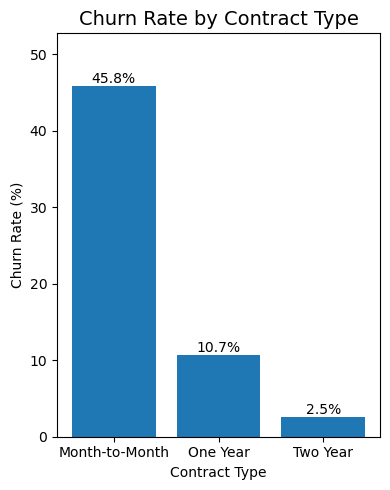

,total_customers,churned_customers,churn_rate_pct
Contract,,,
Month-to-Month,3610,1655,45.844875
One Year,1550,166,10.709677
Two Year,1883,48,2.549124


In [11]:
# Visualize churn rate by contract type

contract_churn = (
    df_clean.groupby("Contract")
    .agg(
        total_customers=("Customer ID", "count"),
        churned_customers=(
            "Customer Status",
            lambda status: (status == "Churned").sum()
        )
    )
)

contract_churn["churn_rate_pct"] = (
    contract_churn["churned_customers"]
    / contract_churn["total_customers"]
    * 100
)

contract_churn = contract_churn.sort_values(
    "churn_rate_pct", ascending=False
)

plt.figure(figsize=(4, 5))
bars = plt.bar(
    contract_churn.index,
    contract_churn["churn_rate_pct"]
)

plt.title("Churn Rate by Contract Type", fontsize=14)
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

for bar, rate in zip(bars, contract_churn["churn_rate_pct"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1f}%",
        ha="center",
        va="bottom"
    )

plt.ylim(0, contract_churn["churn_rate_pct"].max() * 1.15)
plt.tight_layout()

plt.savefig(
    "../images/02_churn_rate_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

contract_churn


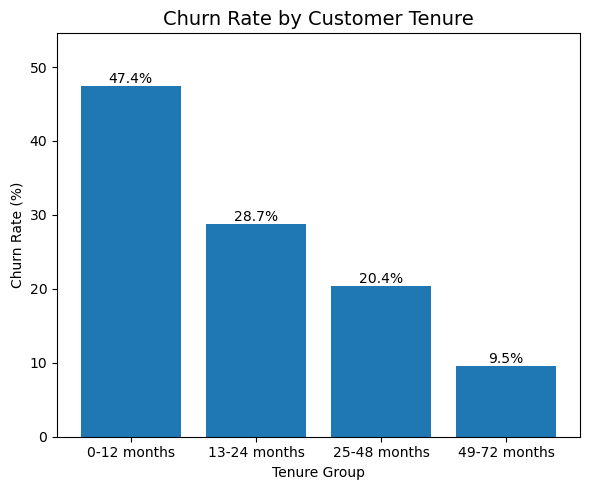

,total_customers,churned_customers,churn_rate_pct
Tenure Group,,,
0-12 months,2186,1037,47.438243
13-24 months,1024,294,28.710938
25-48 months,1594,325,20.388959
49-72 months,2239,213,9.513176


In [14]:
# Visualze churn rate by tenure

df_clean["Tenure Group"] = pd.cut(
    df_clean["Tenure in Months"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"],
    include_lowest=True
)

tenure_churn = (
    df_clean.groupby("Tenure Group", observed=False)
    .agg(
        total_customers=("Customer ID", "count"),
        churned_customers=(
            "Customer Status",
            lambda status: (status == "Churned").sum()
        )
    )
)

tenure_churn["churn_rate_pct"] = (
    tenure_churn["churned_customers"]
    / tenure_churn["total_customers"]
    * 100
)

plt.figure(figsize=(6, 5))
bars = plt.bar(
    tenure_churn.index.astype(str),
    tenure_churn["churn_rate_pct"]
)

plt.title("Churn Rate by Customer Tenure", fontsize=14)
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

for bar, rate in zip(bars, tenure_churn["churn_rate_pct"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1f}%",
        ha="center",
        va="bottom"
    )

plt.ylim(0, tenure_churn["churn_rate_pct"].max() * 1.15)
plt.tight_layout()

plt.savefig(
    "../images/03_churn_rate_by_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

tenure_churn


**Churn Is Highest Among Newer Customers**

Customers with 0–12 months of tenure had the highest churn rate at 47.44%. This fell to 28.71% for customers with 13–24 months of tenure, 20.39% for those with 25–48 months, and 9.51% for customers with 49–72 months.

**Business implication:** Investigate the early customer journey, including onboarding, initial service quality, and support. Targeted follow-up with newer customers may help identify problems before they decide to leave.

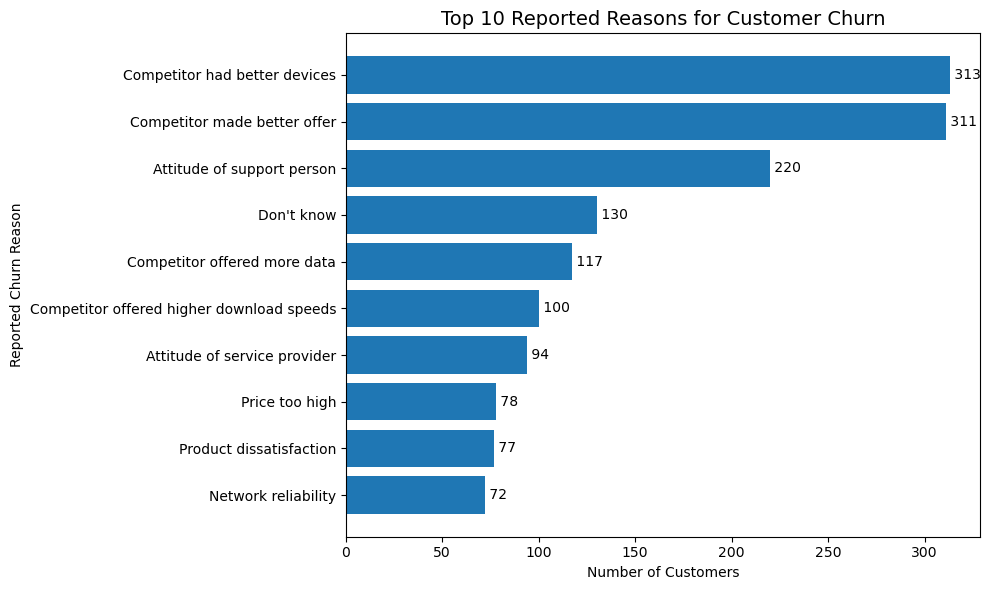

In [15]:
# Visualize the top 10 reported reasons for customer churn

reason_counts = (
    df_clean.loc[df_clean["Customer Status"] == "Churned", "Churn Reason"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
bars = plt.barh(reason_counts.index, reason_counts.values)

plt.title("Top 10 Reported Reasons for Customer Churn", fontsize=14)
plt.xlabel("Number of Customers")
plt.ylabel("Reported Churn Reason")

for bar, count in zip(bars, reason_counts.values):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {count}",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "../images/04_top_churn_reasons.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [7]:
# Verify images are saved

from pathlib import Path

image_folder = Path("../images")

for file in sorted(image_folder.glob("*.png")):
    print(file.name, "-", round(file.stat().st_size / 1024, 1), "KB")


00_telecom_churn_workflow.png - 51.2 KB
01_customer_status_distribution.png - 90.7 KB
02_churn_rate_by_contract.png - 72.7 KB
03_churn_rate_by_tenure.png - 77.5 KB
04_top_churn_reasons.png - 197.4 KB


## Customer Churn Visualizations Summary

### Charts created

1. **Customer Status Distribution:** Visualizes the counts and proportions of customers who stayed, churned, or joined.
2. **Churn Rate by Contract Type:** Compares churn rates across month-to-month, one-year, and two-year contracts.
3. **Churn Rate by Tenure:** Shows that churn rates are highest among customers with 0–12 months of tenure and decline across the observed tenure groups.
4. **Top 10 Reported Churn Reasons:** Highlights the most frequently reported reasons customers gave for leaving.

### Main insights

- Month-to-month customers had a churn rate of approximately 45.84%, compared with 10.71% for one-year contracts and 2.55% for two-year contracts.
- Customers with 0–12 months of tenure had the highest observed tenure-group churn rate, at approximately 47.44%.
- Competitor-related reasons were the largest reported churn category, accounting for 45% of churned customers.

### Visualization skills practiced

Using Matplotlib to create bar charts and horizontal bar charts, adding data labels, calculating percentages, formatting chart titles and axes, saving high-resolution PNG files, and communicating findings through data visualization.